In [19]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.11.9 (v3.11.9:de54cf5be3, Apr  2 2024, 07:12:50) [Clang 13.0.0 (clang-1300.0.29.30)]
Python executable: /Users/mkhdachothmane/Desktop/TP01_Reinforcement_Learning/untitled folder/deep/.venv/bin/python


In [20]:
import pandas as pd
from pathlib import Path

# Localisation du projet
PROJECT_DIR = Path.cwd().parent

# Charger les datasets
train = pd.read_csv(
    PROJECT_DIR / "data" / "sign_mnist_train.csv"
)

test = pd.read_csv(
    PROJECT_DIR / "data" / "sign_mnist_test.csv"
)

print("Train :", train.shape)
print("Test :", test.shape)

display(train.head())

Train : (27455, 785)
Test : (7172, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [21]:
# Afficher les différentes étiquettes
print("Étiquettes :", sorted(train.label.unique()))

# Vérifier les valeurs manquantes
print("Valeurs manquantes :", train.isna().sum().sum())

Étiquettes : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24)]
Valeurs manquantes : 0


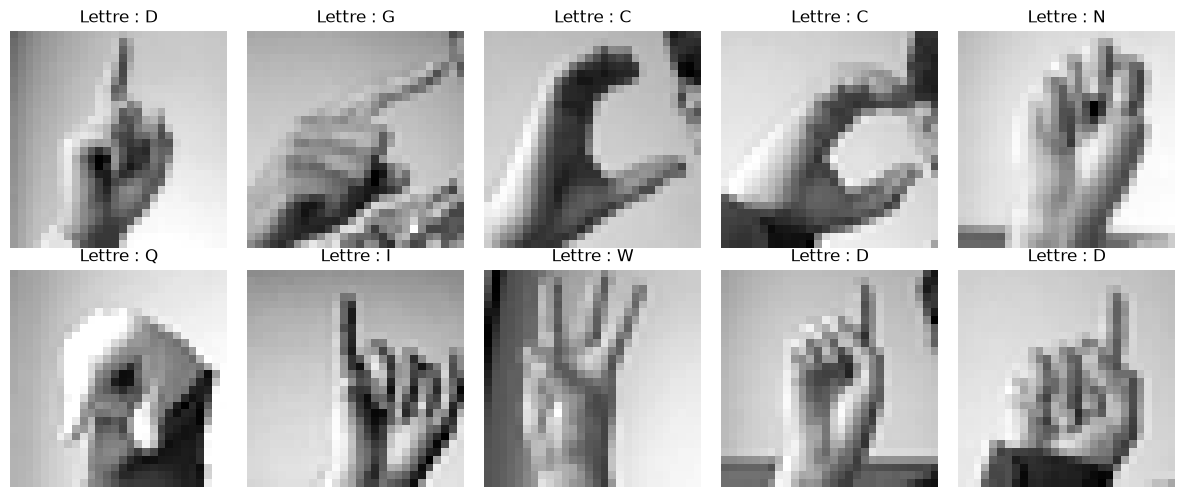

In [22]:
import numpy as np
import matplotlib.pyplot as plt

# Créer une grille de 2 lignes et 5 colonnes
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

# Afficher les 10 premières images
for i, ax in enumerate(axes.flat):

    # Extraire les pixels
    img = train.iloc[i, 1:].to_numpy(dtype=np.uint8)

    # Transformer les 784 pixels en image 28x28
    img = img.reshape(28, 28)

    # Récupérer le label
    label = int(train.iloc[i, 0])

    # Afficher l'image
    ax.imshow(img, cmap="gray")

    # Afficher la lettre
    ax.set_title(f"Lettre : {chr(65 + label)}")

    ax.axis("off")

plt.tight_layout()
plt.show()

In [23]:
# Séparer les images et les labels

X_train = train.drop(columns="label").to_numpy(dtype="float32")
X_test = test.drop(columns="label").to_numpy(dtype="float32")

y_train_orig = train["label"].to_numpy()
y_test_orig = test["label"].to_numpy()


# Redimensionner les images et normaliser les pixels

X_train = X_train.reshape(-1, 28, 28, 1) / 255.0
X_test = X_test.reshape(-1, 28, 28, 1) / 255.0


# Afficher les dimensions

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", y_train_orig.shape)
print("y_test :", y_test_orig.shape)

X_train : (27455, 28, 28, 1)
X_test : (7172, 28, 28, 1)
y_train : (27455,)
y_test : (7172,)


In [24]:
from sklearn.preprocessing import LabelEncoder

# Créer le LabelEncoder
encoder = LabelEncoder()

# Encoder les labels
y_train = encoder.fit_transform(y_train_orig)
y_test = encoder.transform(y_test_orig)

# Afficher les résultats
print("Nombre de classes :", len(encoder.classes_))

print("Étiquettes originales :", encoder.classes_)

print("Étiquettes encodées :", sorted(set(y_train)))

Nombre de classes : 24
Étiquettes originales : [ 0  1  2  3  4  5  6  7  8 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]
Étiquettes encodées : [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23)]


In [25]:
print("========== VÉRIFICATION ==========")

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

print("Pixel minimum :", X_train.min())
print("Pixel maximum :", X_train.max())

print("Nombre de classes :", len(encoder.classes_))

========== VÉRIFICATION ==========
X_train : (27455, 28, 28, 1)
X_test : (7172, 28, 28, 1)
y_train : (27455,)
y_test : (7172,)
Pixel minimum : 0.0
Pixel maximum : 1.0
Nombre de classes : 24


In [26]:
import tensorflow as tf
from tensorflow.keras import layers, models # type: ignore

# Construction du CNN
model = models.Sequential([

    # Input layer
    layers.Input(shape=(28, 28, 1)),

    # First convolution
    layers.Conv2D(
        32, (3, 3),
        activation="relu",
        padding="same"
    ),

    # First pooling
    layers.MaxPooling2D((2, 2)),

    # Second convolution
    layers.Conv2D(
        64, (3, 3),
        activation="relu",
        padding="same"
    ),

    # Second pooling
    layers.MaxPooling2D((2, 2)),

    # Flatten
    layers.Flatten(),

    # Dense layer
    layers.Dense(128, activation="relu"),

    # Dropout
    layers.Dropout(0.3),

    # Output layer
    layers.Dense(24, activation="softmax")
])

# Afficher l'architecture
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,448 (1.62 MB)

 Trainable params: 423,448 (1.62 MB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Compilation du modèle
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modèle compilé avec succès !")

Modèle compilé avec succès !


In [28]:
callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


In [29]:
history = model.fit(
    X_train,
    y_train,
    validation_split=0.2,
    epochs=15,
    batch_size=64,
    callbacks=[callback],
    verbose=1
)

Epoch 1/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 8s 20ms/step - accuracy: 0.4994 - loss: 1.6242 - val_accuracy: 0.8984 - val_loss: 0.4291
Epoch 2/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 6s 17ms/step - accuracy: 0.8249 - loss: 0.5175 - val_accuracy: 0.9741 - val_loss: 0.1513
Epoch 3/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - accuracy: 0.9108 - loss: 0.2729 - val_accuracy: 0.9938 - val_loss: 0.0636
Epoch 4/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.9411 - loss: 0.1798 - val_accuracy: 0.9991 - val_loss: 0.0243
Epoch 5/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 12s 34ms/step - accuracy: 0.9591 - loss: 0.1269 - val_accuracy: 0.9996 - val_loss: 0.0112
Epoch 6/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.9700 - loss: 0.0903 - val_accuracy: 0.9998 - val_loss: 0.0084
Epoch 7/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9768 - loss: 0.0728 - val_accuracy: 1.0000 - val_loss: 0.0040
Epoch 8/15
344/344 ━━━━━━━━━━━━━━━━━━━━ 9s 27ms/step - accuracy: 0.9798 - loss: 0.0619 - val_a

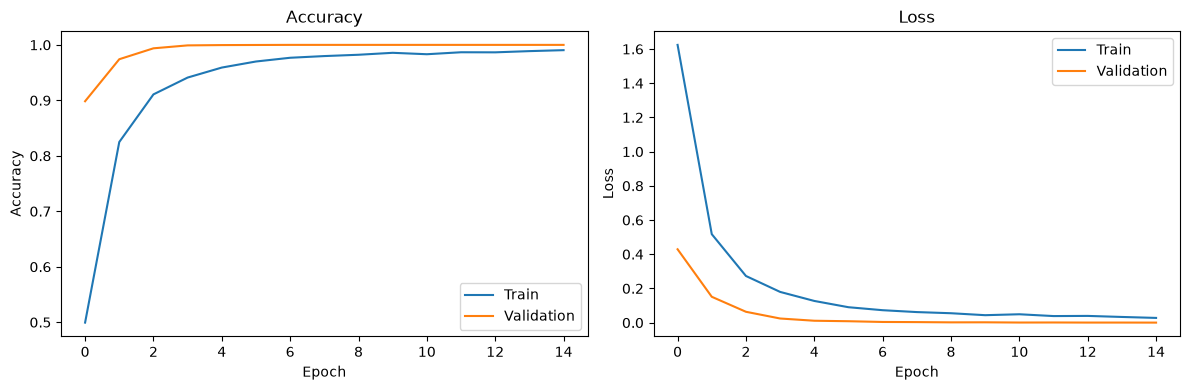

In [30]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Accuracy
axes[0].plot(history.history["accuracy"], label="Train")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

# Loss
axes[1].plot(history.history["loss"], label="Train")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

In [31]:
test_loss, test_acc = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test accuracy : {test_acc:.3f}")
print(f"Test loss : {test_loss:.3f}")

Test accuracy : 0.935
Test loss : 0.291


In [32]:
import numpy as np

# Effectuer les prédictions sur le dataset de test
y_pred_prob = model.predict(X_test)

# Récupérer la classe avec la probabilité maximale
y_pred = np.argmax(y_pred_prob, axis=1)

print("Nombre de prédictions :", len(y_pred))
print("Nombre de vraies étiquettes :", len(y_test))

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Nombre de prédictions : 7172
Nombre de vraies étiquettes : 7172


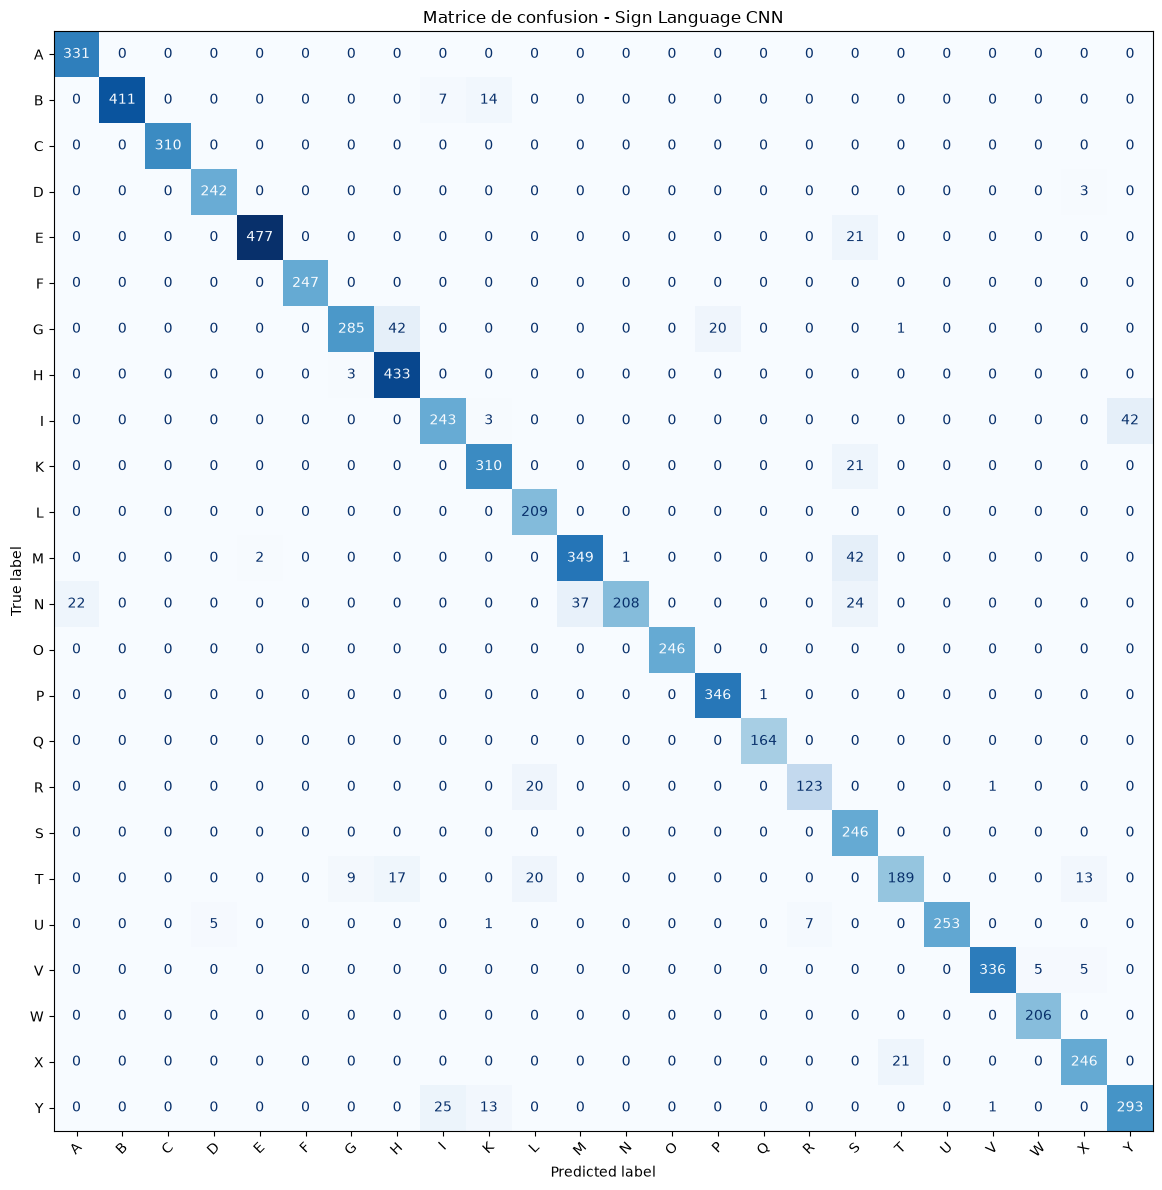

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Construire la matrice de confusion
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(24)
)

# Convertir les labels en lettres
letters = [chr(65 + int(label)) for label in encoder.classes_]

# Afficher la matrice
fig, ax = plt.subplots(figsize=(14, 12))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=letters
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45,
    colorbar=False
)

plt.title("Matrice de confusion - Sign Language CNN")
plt.tight_layout()
plt.show()

In [34]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    y_pred,
    labels=np.arange(24),
    target_names=letters,
    zero_division=0
)

print(report)

              precision    recall  f1-score   support

           A       0.94      1.00      0.97       331
           B       1.00      0.95      0.98       432
           C       1.00      1.00      1.00       310
           D       0.98      0.99      0.98       245
           E       1.00      0.96      0.98       498
           F       1.00      1.00      1.00       247
           G       0.96      0.82      0.88       348
           H       0.88      0.99      0.93       436
           I       0.88      0.84      0.86       288
           K       0.91      0.94      0.92       331
           L       0.84      1.00      0.91       209
           M       0.90      0.89      0.89       394
           N       1.00      0.71      0.83       291
           O       1.00      1.00      1.00       246
           P       0.95      1.00      0.97       347
           Q       0.99      1.00      1.00       164
           R       0.95      0.85      0.90       144
           S       0.69    

Nombre total d'erreurs : 469


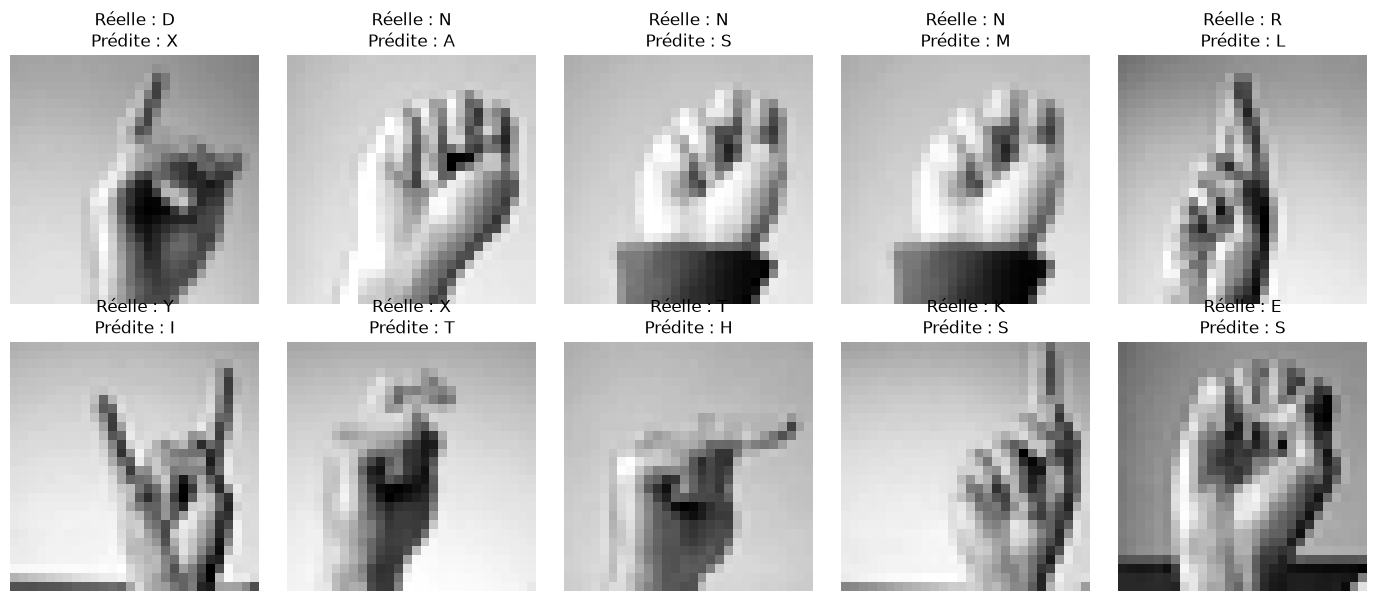

In [35]:
# Identifier les indices des erreurs
errors = np.where(y_pred != y_test)[0]

print("Nombre total d'erreurs :", len(errors))

# Afficher les 10 premières erreurs
fig, axes = plt.subplots(2, 5, figsize=(14, 6))

for i, ax in enumerate(axes.flat):

    if i < len(errors):
        idx = errors[i]

        img = X_test[idx].reshape(28, 28)

        true_label = encoder.inverse_transform([y_test[idx]])[0]
        pred_label = encoder.inverse_transform([y_pred[idx]])[0]

        ax.imshow(img, cmap="gray")

        ax.set_title(
            f"Réelle : {chr(65 + true_label)}\n"
            f"Prédite : {chr(65 + pred_label)}"
        )

    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data" / "raw"

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

print("Train exists:", (DATA_DIR / "sign_mnist_train.csv").exists())
print("Test exists:", (DATA_DIR / "sign_mnist_test.csv").exists())

In [36]:
from pathlib import Path

# Créer le dossier models
models_dir = PROJECT_DIR / "models"
models_dir.mkdir(exist_ok=True)

# Sauvegarder le modèle
model.save(models_dir / "sign_language_cnn.keras")

print("Modèle sauvegardé avec succès !")

Modèle sauvegardé avec succès !


In [1]:
from pathlib import Path

# Racine du projet
PROJECT_DIR = Path.cwd().resolve()

# Si le notebook est lancé depuis notebooks/
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Chemins
DATA_DIR = PROJECT_DIR / "data" / "raw"
MODEL_PATH = PROJECT_DIR / "models" / "sign_language_cnn.keras"

# Vérifications
print("Project:", PROJECT_DIR)
print("Train dataset:", (DATA_DIR / "sign_mnist_train.csv").exists())
print("Test dataset:", (DATA_DIR / "sign_mnist_test.csv").exists())
print("CNN model:", MODEL_PATH.exists())

Project: /Users/mkhdachothmane/Desktop/TP01_Reinforcement_Learning/untitled folder/deep
Train dataset: True
Test dataset: True
CNN model: True
